<a href="https://colab.research.google.com/github/Gerry004p/Cyber-Shujaa/blob/main/Deep_Learning_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
'''
Name: Gerald Mawili Musyoki
ID:   CS-DA02-25026
Title:Deep Learning
'''

'\nName: Gerald Mawili Musyoki\nID:   CS-DA02-25026\nTitle:Deep Learning\n'

In [ ]:
#import libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
#load the data
(X_train, y_train), (X_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


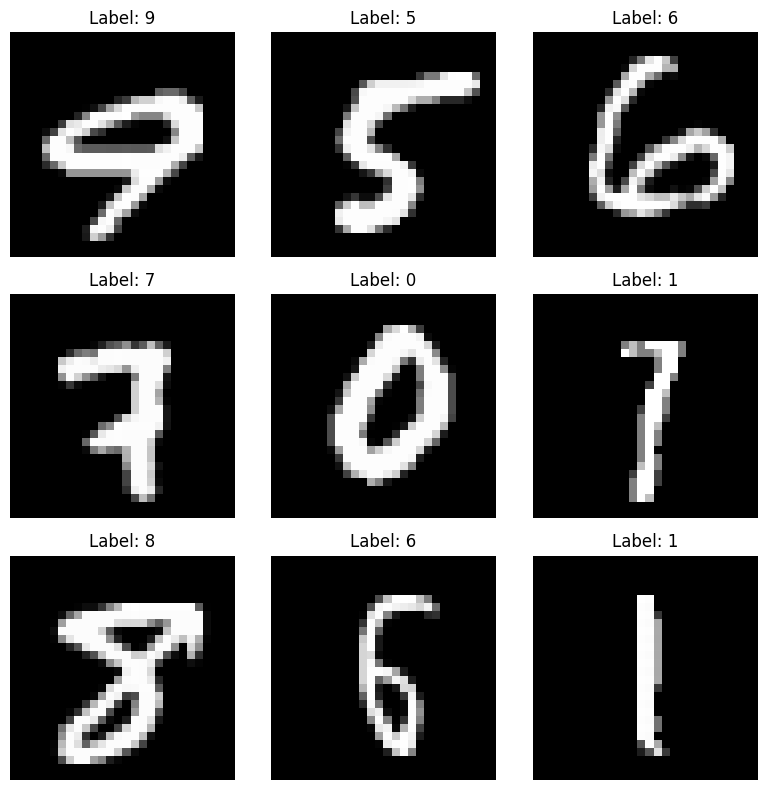

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Visualize 9 random images
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
axes = axes.flatten()
for i in np.arange(9):
    index = np.random.randint(0, len(X_train)) # Pick a random index
    axes[i].imshow(X_train[index], cmap='gray')
    axes[i].set_title(f'Label: {y_train[index]}')
    axes[i].axis('off')
plt.tight_layout()
plt.show()

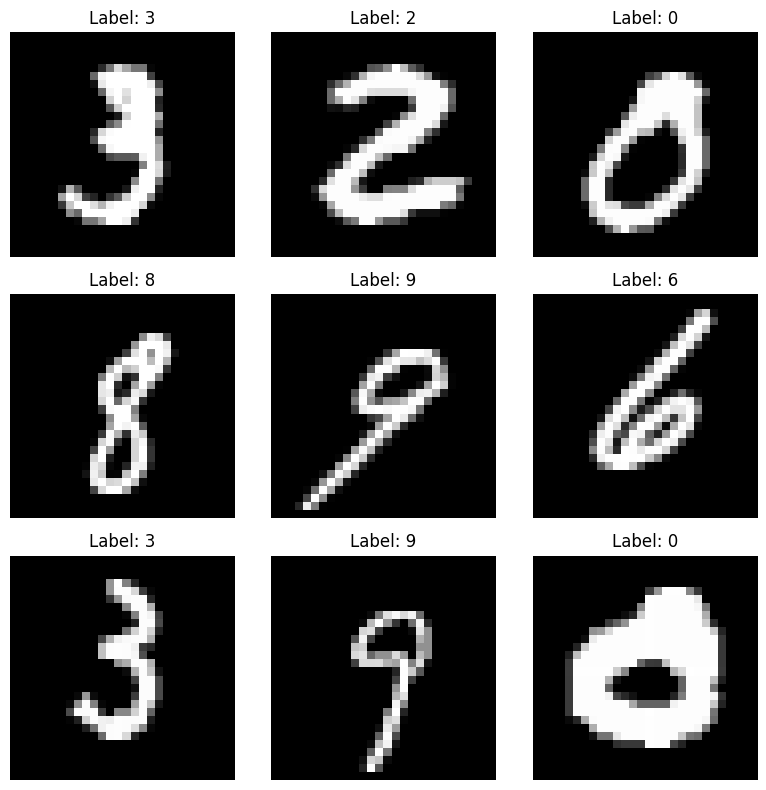

In [ ]:
#preprocess the data
X_train = X_train/255.0 #normalize pixel values to [0,1]
X_test = X_test/255.0
y_train_cat=to_categorical(y_train,10) #one-hot encode labels
y_test_cat=to_categorical(y_test,10)
#plot some digits from the dataset
selected_indices = [10,25,75,300,501,999,1234,1500,1999]
plt.figure(figsize=(8,8))
for i, index in enumerate(selected_indices):
    plt.subplot(3,3,i+1)
    plt.imshow(X_train[index], cmap='gray')
    plt.title(f'Label: {y_train[index]}')
    plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
#build the ANN model
model=Sequential([Flatten(input_shape=(28,28)),Dense(128,activation='relu'),Dropout(0,3),Dense(64,activation='relu'),Dropout(0,3),Dense(10,activation='softmax')])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
#compiled the model
model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [ ]:
# Train the model
history = model.fit(X_train, y_train_cat, epochs=10, batch_size=32, validation_split=0.2)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8620 - loss: 0.4792 - val_accuracy: 0.9553 - val_loss: 0.1526
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9634 - loss: 0.1220 - val_accuracy: 0.9651 - val_loss: 0.1173
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9760 - loss: 0.0793 - val_accuracy: 0.9708 - val_loss: 0.0994
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9820 - loss: 0.0566 - val_accuracy: 0.9674 - val_loss: 0.1116
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9856 - loss: 0.0447 - val_accuracy: 0.9725 - val_loss: 0.0976
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9909 - loss: 0.0293 - val_accuracy: 0.9718 - val_loss: 0.1007
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9919 - loss: 0.0254 - val_accuracy: 0.9730 - val_loss: 0.0985
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9932 - loss: 0.0

In [ ]:
# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test_cat, verbose=0)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

Test Loss: 0.0930
Test Accuracy: 0.9772


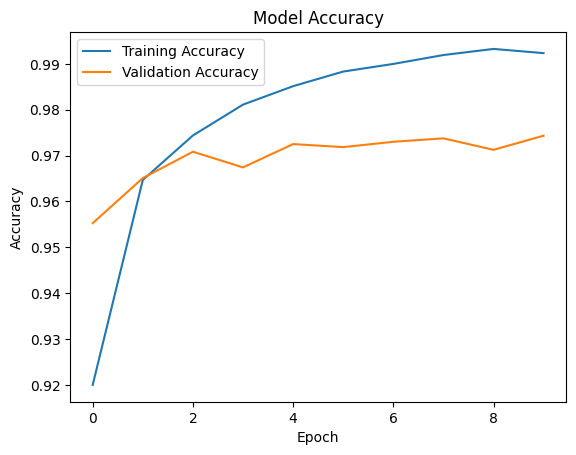

In [ ]:
#visualize training history
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


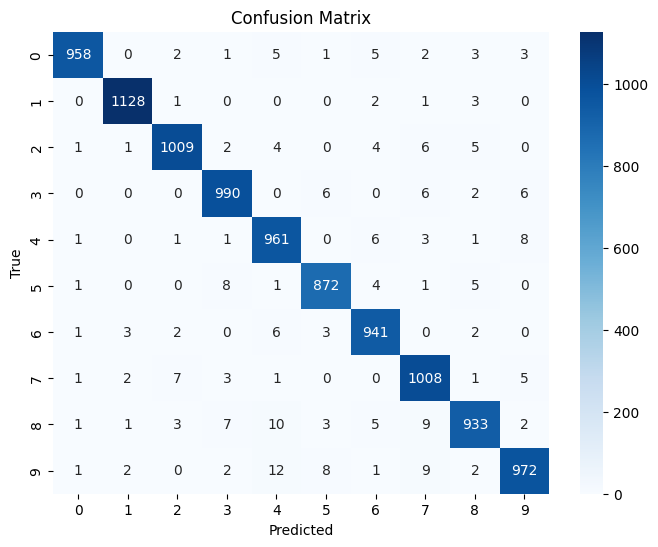

In [ ]:
#confusion matrix
y_pred=model.predict(X_test)
y_pred_classes=np.argmax(y_pred,axis=1)
cm= confusion_matrix(y_test,y_pred_classes)
plt.figure(figsize=(8,6))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
#classification report
print(classification_report(y_test,y_pred_classes))

              precision    recall  f1-score   support

           0       0.99      0.98      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.98      0.98      1032
           3       0.98      0.98      0.98      1010
           4       0.96      0.98      0.97       982
           5       0.98      0.98      0.98       892
           6       0.97      0.98      0.98       958
           7       0.96      0.98      0.97      1028
           8       0.97      0.96      0.97       974
           9       0.98      0.96      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



In [ ]:
#save and reload the model
model.save('mnist_ann_model.h5')

from tensorflow.keras.models import load_model
reloaded_model= load_model('mnist_ann_model.h5')
reloaded_model.evaluate(X_test,y_test_cat)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9735 - loss: 0.1096


[0.0929577574133873, 0.9771999716758728]